# 01 · Análisis exploratorio (EDA) — UNSW-NB15

Responde la pregunta 1 de la guía: **¿qué podemos aprender de estos datos?**

1. Procedencia y verificación de los archivos
2. Estructura: variables de entrada vs. respuestas
3. Clases (binaria y familia de ataque)
4. Valores ausentes y valores "raros"
5. Repeticiones: duplicados, etiquetas contradictorias y solapamiento train/test
6. ¿El `id` significa algo?
7. Variables categóricas y numéricas
8. Diferencias entre train y test
9. Decisiones que se derivan para la preparación de datos

Datos: `UNSW_NB15_training-set.csv` y `UNSW_NB15_testing-set.csv` (partición oficial de UNSW).

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path("../data/raw")
TARGET, FAMILY, ID = "label", "attack_cat", "id"

# Paleta categórica validada (CVD-safe): slot 1 = Normal, slot 2 = Ataque
C_NORMAL, C_ATTACK = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 60)

## 1. Procedencia y verificación

Los CSV se obtuvieron de la copia en GitHub indicada por el docente (commit `44bbd02`) y
se contrastaron con la descarga oficial del SharePoint de UNSW (carpeta *CSV Files*, versión
del 2024-02-09): **son idénticos byte a byte**. El docente advierte que en otras copias los nombres
train/test están intercambiados, así que verificamos el número de filas esperado.

In [2]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# utf-8-sig: el archivo trae BOM, sin esto la primera columna se llama '\ufeffid'
train = pd.read_csv(RAW / "UNSW_NB15_training-set.csv", encoding="utf-8-sig")
test = pd.read_csv(RAW / "UNSW_NB15_testing-set.csv", encoding="utf-8-sig")

assert len(train) == 175_341, "¿train y test intercambiados?"
assert len(test) == 82_332, "¿train y test intercambiados?"
pd.DataFrame({
    "archivo": ["training-set", "testing-set"],
    "filas": [len(train), len(test)],
    "columnas": [train.shape[1], test.shape[1]],
    "sha256": [sha256(RAW / "UNSW_NB15_training-set.csv")[:16] + "…",
               sha256(RAW / "UNSW_NB15_testing-set.csv")[:16] + "…"],
})

,archivo,filas,columnas,sha256
0,training-set,175341,45,bec7dd5ec88dc2a0…
1,testing-set,82332,45,734fe6642edf758f…


## 2. Estructura: qué está disponible al predecir y qué es respuesta

In [3]:
features_doc = pd.read_csv(RAW / "NUSW-NB15_features.csv", encoding="latin-1")
features_doc.columns = features_doc.columns.str.strip()
features_doc["Name"] = features_doc["Name"].str.strip().str.lower()
doc = features_doc.set_index("Name")[["Type", "Description"]]

FEATURES = [c for c in train.columns if c not in (ID, TARGET, FAMILY)]
CAT = train[FEATURES].select_dtypes("object").columns.tolist()
NUM = [c for c in FEATURES if c not in CAT]
print(f"{len(FEATURES)} variables de entrada: {len(NUM)} numéricas, {len(CAT)} categóricas {CAT}")
print(f"Respuestas: {TARGET!r} (0 normal / 1 ataque) y {FAMILY!r} (familia)  ·  Identificador: {ID!r}")
doc.reindex(FEATURES).head(12)

42 variables de entrada: 39 numéricas, 3 categóricas ['proto', 'service', 'state']
Respuestas: 'label' (0 normal / 1 ataque) y 'attack_cat' (familia)  ·  Identificador: 'id'


,Type,Description
Name,,
dur,Float,Record total duration
proto,nominal,Transaction protocol
service,nominal,"http, ftp, smtp, ssh, dns, ftp-data ,irc and ..."
state,nominal,Indicates to the state and its dependent proto...
spkts,integer,Source to destination packet count
dpkts,integer,Destination to source packet count
sbytes,Integer,Source to destination transaction bytes
dbytes,Integer,Destination to source transaction bytes
rate,NaN,NaN


- **Respuestas (no se usan como entrada):** `label` (objetivo principal) y `attack_cat`
  (ampliación). `attack_cat` determina `label` exactamente (`Normal` ⇔ 0), así que usarla
  como entrada sería fuga total de la respuesta.
- **Identificador:** `id` — se analiza en la sección 6.
- Las 42 restantes describen la conexión. Algunas (p. ej. `rate`) no aparecen en
  `NUSW-NB15_features.csv`, que documenta el dataset completo y no esta partición.
  Las variables cubren flujo, bytes, TTL, tiempos y contadores `ct_*`.
  Nota: los `ct_*` se calculan sobre ventanas de las últimas 100 conexiones; en producción
  requerirían ese estado, pero están disponibles en el momento de predecir.

In [4]:
assert (train[FAMILY].eq("Normal") == train[TARGET].eq(0)).all()
assert (test[FAMILY].eq("Normal") == test[TARGET].eq(0)).all()
print("attack_cat == 'Normal'  <=>  label == 0  en train y test")

attack_cat == 'Normal'  <=>  label == 0  en train y test


## 3. Clases

In [5]:
def class_table(df):
    return df[TARGET].map({0: "Normal", 1: "Ataque"}).value_counts()

bin_tbl = pd.DataFrame({"train": class_table(train), "test": class_table(test)})
bin_tbl["train %"] = (bin_tbl["train"] / len(train) * 100).round(1)
bin_tbl["test %"] = (bin_tbl["test"] / len(test) * 100).round(1)

fam = pd.DataFrame({"train": train[FAMILY].value_counts(), "test": test[FAMILY].value_counts()})
fam["train %"] = (fam["train"] / len(train) * 100).round(2)
fam["test %"] = (fam["test"] / len(test) * 100).round(2)
display(bin_tbl, fam)

,train,test,train %,test %
label,,,,
Ataque,119341,45332,68.1,55.1
Normal,56000,37000,31.9,44.9


,train,test,train %,test %
attack_cat,,,,
Normal,56000,37000,31.94,44.94
Generic,40000,18871,22.81,22.92
Exploits,33393,11132,19.04,13.52
Fuzzers,18184,6062,10.37,7.36
DoS,12264,4089,6.99,4.97
Reconnaissance,10491,3496,5.98,4.25
Analysis,2000,677,1.14,0.82
Backdoor,1746,583,1.00,0.71
Shellcode,1133,378,0.65,0.46


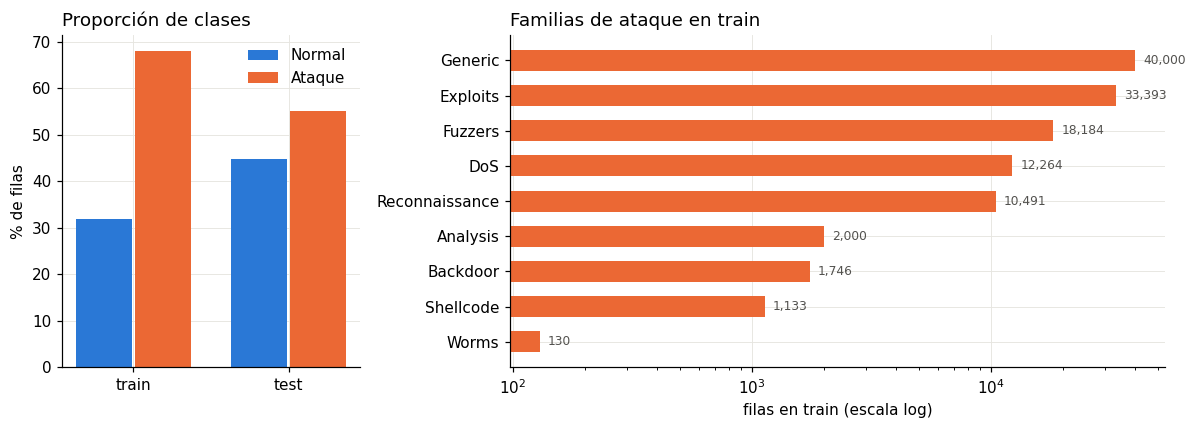

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2.2]})

ax = axes[0]
x = np.arange(2)
for i, (lab, col) in enumerate([("Normal", C_NORMAL), ("Ataque", C_ATTACK)]):
    vals = [bin_tbl.loc[lab, "train %"], bin_tbl.loc[lab, "test %"]]
    ax.bar(x + (i - 0.5) * 0.38, vals, width=0.36, color=col, label=lab)
ax.set_xticks(x, ["train", "test"])
ax.set_ylabel("% de filas")
ax.set_title("Proporción de clases", loc="left")
ax.legend(frameon=False)

ax = axes[1]
f = fam.drop("Normal").sort_values("train")
ax.barh(f.index, f["train"], color=C_ATTACK, height=0.6)
ax.set_xscale("log")
ax.set_xlabel("filas en train (escala log)")
ax.set_title("Familias de ataque en train", loc="left")
for y, v in enumerate(f["train"]):
    ax.text(v * 1.08, y, f"{v:,}", va="center", fontsize=8, color="#52514e")
plt.tight_layout()

**Lectura:**
- En train el **68 % son ataques** y en test el **55 %**: la "clase positiva" es mayoritaria,
  al revés de una red real, donde el ataque es raro. Por eso la *accuracy* no informa mucho:
  un modelo que diga siempre "ataque" acierta 68 % en train.
- La proporción **cambia entre train y test** → la precisión y la tasa de falsas alarmas
  dependen de la prevalencia; hay que reportarlas sabiendo esto.
- Familias muy desbalanceadas: `Generic` y `Exploits` dominan; `Worms` (130 filas),
  `Shellcode` y `Backdoor` son escasas. Para la ampliación multiclase, macro-F1 será exigente.

## 4. Valores ausentes y valores raros

In [7]:
print("NaN en train:", int(train.isna().sum().sum()), " · NaN en test:", int(test.isna().sum().sum()))
dash = pd.DataFrame({c: [(train[c] == "-").mean() * 100, (test[c] == "-").mean() * 100] for c in CAT},
                    index=["train % '-'", "test % '-'"]).round(1)
dash

NaN en train: 0  · NaN en test: 0


,proto,service,state
train % '-',0.0,53.7,0.0
test % '-',0.0,57.3,0.0


In [8]:
# Variables documentadas como binarias que tienen otros valores
for c in ["is_ftp_login", "is_sm_ips_ports"]:
    print(c, "doc:", doc.loc[c, "Type"].strip(), "| valores train:", sorted(train[c].unique()))
print("negativos en numéricas:", (train[NUM] < 0).sum().loc[lambda s: s > 0].to_dict() or "ninguno")

is_ftp_login doc: Binary | valores train: [np.int64(0), np.int64(1), np.int64(2), np.int64(4)]
is_sm_ips_ports doc: Binary | valores train: [np.int64(0), np.int64(1)]
negativos en numéricas: ninguno


- No hay `NaN`, pero **`service = '-'` (≈54 %) es un ausente codificado**: significa "servicio
  no identificado". No se imputa: se trata como una categoría propia, porque su ausencia es
  informativa.
- `is_ftp_login` está documentada como binaria pero toma valores {0, 1, 2, 4}: es un problema
  de calidad del dataset. Se deja como numérica y se documenta.

## 5. Repeticiones

In [9]:
def feature_hash(df):
    return pd.util.hash_pandas_object(df[FEATURES], index=False)

rows = []
for name, df in [("train", train), ("test", test)]:
    h = feature_hash(df)
    conflicts = df.assign(_h=h).groupby("_h")[TARGET].nunique()
    rows.append({
        "conjunto": name,
        "filas": len(df),
        "duplicados exactos (sin id)": int(df.drop(columns=ID).duplicated().sum()),
        "duplicados de features": int(h.duplicated().sum()),
        "% duplicados features": round(h.duplicated().mean() * 100, 1),
        "filas únicas": int(h.nunique()),
        "grupos con label contradictorio": int((conflicts > 1).sum()),
    })
dups = pd.DataFrame(rows).set_index("conjunto")
dups

,filas,duplicados exactos (sin id),duplicados de features,% duplicados features,filas únicas,grupos con label contradictorio
conjunto,,,,,,
train,175341,67601,74301,42.4,101040,229
test,82332,26387,28386,34.5,53946,6


In [10]:
h_tr, h_te = feature_hash(train), feature_hash(test)
in_train = h_te.isin(set(h_tr))
print(f"Filas de test cuyas features exactas aparecen en train: {in_train.sum():,} ({in_train.mean():.1%})")
print("…por clase en test:", test[in_train][TARGET].map({0: 'Normal', 1: 'Ataque'}).value_counts().to_dict())

# ¿Qué familias se repiten más?
dup_rate = train.assign(dup=h_tr.duplicated(keep=False)).groupby(FAMILY)["dup"].mean().mul(100).round(1)
dup_rate.sort_values(ascending=False).rename("% filas en grupo duplicado (train)")

Filas de test cuyas features exactas aparecen en train: 8,541 (10.4%)
…por clase en test: {'Ataque': 7069, 'Normal': 1472}


attack_cat
Generic           97.9
Analysis          85.4
DoS               80.1
Backdoor          77.1
Exploits          49.7
Reconnaissance    44.0
Fuzzers           25.6
Normal            10.8
Worms             10.0
Shellcode          7.2
Name: % filas en grupo duplicado (train), dtype: float64

**Lectura:**
- **≈42 % de las filas de train son repeticiones** de otra fila con exactamente las mismas
  variables. Se concentran en algunas familias de ataque: **98 % de `Generic`** y ~80 % de
  `Analysis`, `DoS` y `Backdoor` están en grupos repetidos (la herramienta de laboratorio genera
  muchas conexiones idénticas), frente a ~11 % del tráfico normal.
- Hay grupos de filas **idénticas con etiqueta distinta**: ningún modelo puede separarlas, así
  que existe un techo de error irreducible.
- **≈10 % del test aparece literalmente en train.** Si además separamos la validación al azar
  dentro de train, una copia puede quedar en entrenamiento y otra en validación: el modelo
  "memoriza" y la validación se ve mejor de lo que es.

**Decisión propuesta:** separar la validación **por grupos de filas idénticas**
(`StratifiedGroupKFold` / `GroupShuffleSplit` con el hash de las features como grupo), de modo
que ninguna fila repetida cruce de entrenamiento a validación. Como experimento, comparar
entrenar con o sin deduplicar (deduplicar cambia la población: menos peso a los ataques masivos).
El test oficial se deja intacto; se reporta además la métrica sobre el test **sin** las filas
vistas en train, para medir cuánto infla el resultado ese solapamiento.

## 6. ¿El `id` significa algo?

id es 1..n consecutivo: True True


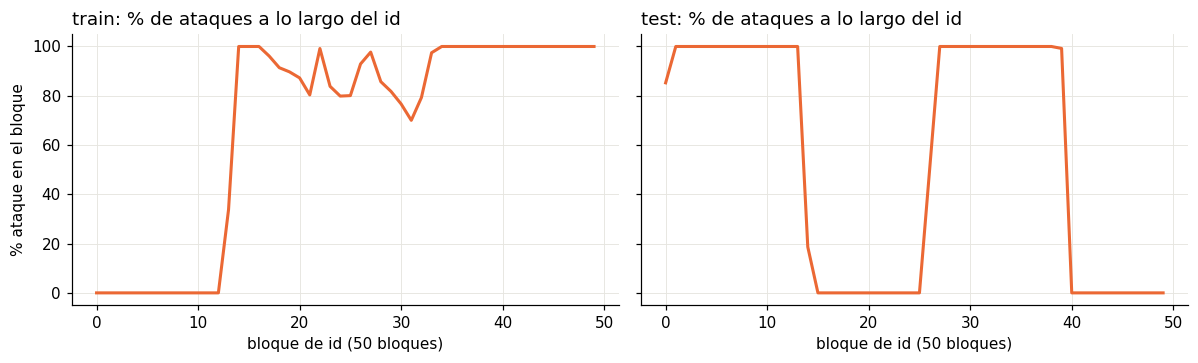

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (name, df) in zip(axes, [("train", train), ("test", test)]):
    b = df.groupby(pd.cut(df[ID], 50, labels=False))[TARGET].mean() * 100
    ax.plot(b.index, b.values, color=C_ATTACK, linewidth=2)
    ax.set_title(f"{name}: % de ataques a lo largo del id", loc="left")
    ax.set_xlabel("bloque de id (50 bloques)")
axes[0].set_ylabel("% ataque en el bloque")
plt.tight_layout()

print("id es 1..n consecutivo:", (train[ID] == np.arange(1, len(train) + 1)).all(),
      (test[ID] == np.arange(1, len(test) + 1)).all())

El `id` es solo el **número de fila (1…n)**, reiniciado en cada archivo, y los archivos están
**ordenados por clase/familia** (en train los primeros bloques son todos normales y los
últimos todos ataques). Por eso el `id` "predice" muy bien en train, pero solo refleja cómo
se armó el archivo: en test el mismo `id` corresponde a otra cosa.

**Decisión:** eliminar `id` de las entradas y **barajar** antes de cualquier partición
(nunca cortar train/validación por posición).

## 7. Variables

### 7.1 Categóricas

In [12]:
for c in CAT:
    unseen = sorted(set(test[c]) - set(train[c]))
    print(f"{c:8s} categorías train={train[c].nunique():3d} test={test[c].nunique():3d}  no vistas en train: {unseen}")
pd.crosstab(train["state"], train[TARGET].map({0: "Normal", 1: "Ataque"}), margins=True)

proto    categorías train=133 test=131  no vistas en train: []


service  categorías train= 13 test= 13  no vistas en train: []
state    categorías train=  9 test=  7  no vistas en train: ['ACC', 'CLO']


label,Ataque,Normal,All
state,,,
CON,1053,12099,13152
ECO,0,12,12
FIN,40650,37175,77825
INT,76560,5715,82275
PAR,0,1,1
REQ,1066,925,1991
RST,12,71,83
URN,0,1,1
no,0,1,1


In [13]:
top_proto = train["proto"].value_counts()
print("proto: top 5 cubren", f"{top_proto.head(5).sum() / len(train):.1%}", "|", top_proto.head(5).to_dict())
print("protocolos con < 0.1% de filas:", (top_proto / len(train) < 0.001).sum(), "de", len(top_proto))
pd.crosstab(train["service"], train[TARGET].map({0: "Normal", 1: "Ataque"}), normalize="index").mul(100).round(1)

proto: top 5 cubren 91.7% | {'tcp': 79946, 'udp': 63283, 'unas': 12084, 'arp': 2859, 'ospf': 2595}
protocolos con < 0.1% de filas: 118 de 133


label,Ataque,Normal
service,,
-,61.2,38.8
dhcp,100.0,0.0
dns,84.2,15.8
ftp,64.5,35.5
ftp-data,36.1,63.9
http,71.4,28.6
irc,100.0,0.0
pop3,99.6,0.4
radius,83.3,16.7


- `proto` tiene **133 valores** con cola muy larga → conviene agrupar los poco frecuentes
  como `other` (o usar un codificador que ignore categorías desconocidas).
- `state` tiene en test dos valores (`ACC`, `CLO`) **que no existen en train** → el
  preprocesamiento debe tolerar categorías nuevas (`OneHotEncoder(handle_unknown="ignore")`).

### 7.2 Numéricas: escala y relación con la clase

In [14]:
desc = train[NUM].describe(percentiles=[0.5, 0.99]).T
desc["asimetría"] = train[NUM].skew()
desc.sort_values("asimetría", ascending=False).head(10).round(2)

,count,mean,std,min,50%,99%,max,asimetría
trans_depth,175341.0,0.11,0.78,0.0,0.00,1.00,172.00,167.34
response_body_len,175341.0,2144.29,54207.97,0.0,0.00,3924.00,6558056.00,76.34
sbytes,175341.0,8844.84,174765.64,28.0,430.00,74125.40,12965233.00,45.30
sloss,175341.0,4.95,66.01,0.0,0.00,38.00,4803.00,44.75
dloss,175341.0,6.95,52.73,0.0,0.00,178.60,5484.00,41.38
spkts,175341.0,20.30,136.89,1.0,2.00,234.00,9616.00,40.22
dbytes,175341.0,14928.92,143654.22,0.0,164.00,474367.80,14655550.00,39.76
dpkts,175341.0,18.97,110.26,0.0,2.00,400.00,10974.00,36.76
dinpkt,175341.0,88.22,987.09,0.0,0.01,441.65,56716.82,29.68
djit,175341.0,604.35,4061.04,0.0,0.00,9466.02,289388.27,29.54


In [15]:
corr = train[NUM].corrwith(train[TARGET]).rename("corr con label")
top = corr.abs().sort_values(ascending=False).head(12).index
corr[top].round(3).to_frame()

,corr con label
sttl,0.693
ct_state_ttl,0.578
dload,-0.394
ct_dst_sport_ltm,0.357
dmean,-0.342
rate,0.338
swin,-0.334
dwin,-0.320
ct_src_dport_ltm,0.306
ct_dst_src_ltm,0.304


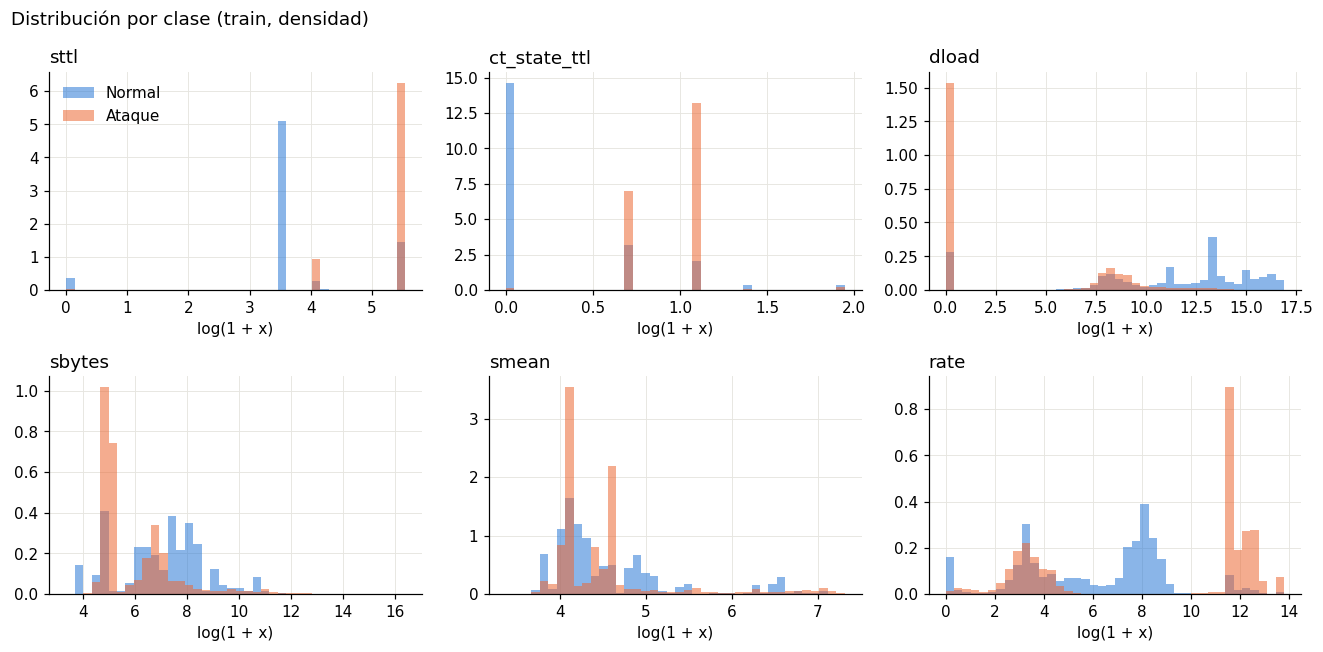

In [16]:
show = ["sttl", "ct_state_ttl", "dload", "sbytes", "smean", "rate"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), show):
    v = np.log1p(train[c].clip(lower=0))
    bins = np.histogram_bin_edges(v, 40)
    for lab, col, name in [(0, C_NORMAL, "Normal"), (1, C_ATTACK, "Ataque")]:
        ax.hist(v[train[TARGET] == lab], bins=bins, color=col, alpha=0.55, density=True, label=name)
    ax.set_title(c, loc="left")
    ax.set_xlabel("log(1 + x)")
axes[0, 0].legend(frameon=False)
fig.suptitle("Distribución por clase (train, densidad)", x=0.01, ha="left")
plt.tight_layout()

In [17]:
pd.crosstab(train["sttl"], train[TARGET].map({0: "Normal", 1: "Ataque"})).loc[lambda d: d.sum(1) > 100]

label,Ataque,Normal
sttl,,
0,303,2859
31,0,39455
62,15514,2167
64,0,181
254,103513,11230


**Lectura:**
- Las numéricas son **muy asimétricas** (bytes, cargas, tiempos): conviene `log1p` + escalado
  para modelos lineales; para árboles no es necesario.
- **`sttl` (TTL origen→destino) separa gran parte de las clases por sí sola**: `sttl=31`
  (39 mil filas) es **siempre** normal, y el 87 % de los ataques tiene `sttl=254` (aunque
  ese valor también incluye 11 mil normales). Es un **artefacto del laboratorio** (las máquinas
  atacantes tenían otro sistema operativo/configuración), no una propiedad general del ataque.
  `ct_state_ttl` se deriva de él. Un modelo puede apoyarse en ese atajo y no generalizar a una
  red real. Vale la pena un experimento **con y sin las variables de TTL** para medir cuánto
  depende el modelo de él.

## 8. Diferencias entre train y test

In [18]:
shift = pd.DataFrame({
    "mediana train": train[NUM].median(),
    "mediana test": test[NUM].median(),
})
# diferencia estandarizada de medias en escala log
lt, le = np.log1p(train[NUM].clip(lower=0)), np.log1p(test[NUM].clip(lower=0))
shift["dif. estandarizada (log)"] = ((le.mean() - lt.mean()) / lt.std()).round(2)
shift.reindex(shift["dif. estandarizada (log)"].abs().sort_values(ascending=False).index).head(10)

,mediana train,mediana test,dif. estandarizada (log)
synack,0.0,4.410000e-04,0.18
ct_dst_src_ltm,3.0,3.000000e+00,-0.18
tcprtt,0.0,5.510000e-04,0.17
ackdat,0.0,8.000000e-05,0.15
swin,0.0,2.550000e+02,0.14
dttl,29.0,2.900000e+01,0.12
ct_dst_sport_ltm,1.0,1.000000e+00,-0.11
stcpb,0.0,2.788886e+07,0.11
dwin,0.0,2.550000e+02,0.10
dtcpb,0.0,2.856975e+07,0.10


El cambio principal entre archivos es de **prevalencia y mezcla de familias** (68 % → 55 %
ataques; menos `Exploits` y `Fuzzers` en test). El cambio en las variables numéricas es
pequeño (diferencia estandarizada ≤ 0.2). La validación sale de train, así que **es esperable que el
resultado en test sea algo peor** que en validación; se reporta tal cual.

## 9. Decisiones para la preparación de datos

| # | Hallazgo | Decisión |
|---|----------|----------|
| 1 | El archivo trae BOM | Leer con `encoding="utf-8-sig"` |
| 2 | `attack_cat` determina `label` | Nunca usarla como entrada en el problema binario |
| 3 | `id` = número de fila de un archivo ordenado por clase | Eliminarlo; barajar antes de partir |
| 4 | ≈42 % de train son filas repetidas; algunas con etiqueta contradictoria | Validación agrupada por hash de features (las copias no cruzan la partición). Experimento: con vs. sin deduplicar |
| 5 | ≈10 % del test está en train | Test oficial intacto, usado **una sola vez**; reportar también la métrica sin las filas vistas |
| 6 | `service='-'` es ausencia codificada | Mantener como categoría propia |
| 7 | `state` tiene categorías en test que no hay en train; `proto` tiene cola larga | `OneHotEncoder(handle_unknown="ignore")` y agrupar categorías raras |
| 8 | Numéricas muy asimétricas | `log1p` + escalado para modelos lineales |
| 9 | `sttl`/`ct_state_ttl` son un atajo del laboratorio | Experimento con y sin variables de TTL |
| 10 | Prevalencia de ataque 68 % (train) vs 55 % (test) | Usar recall, precisión, FPR y macro-F1, no accuracy; umbral elegido en validación |

**Particiones:** `train` oficial → entrenamiento (≈80 %) + validación (≈20 %), estratificada
y agrupada, semilla fija. `test` oficial → evaluación final, una sola vez.

**Limitación:** UNSW-NB15 es tráfico sintético de laboratorio (2015); un buen resultado aquí
no prueba eficacia sobre una red actual.